In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface
import nilearn.plotting

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [ ]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
results_dir = os.path.join(project_dir, '...')

In [ ]:
## demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## ctx
ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', 'ctx_ige_durill.csv'), index_col=0)

## sv
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', 'sv_ige_durill.csv'), index_col=0)

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    "my_rdbu", ["#174fa0", "#2f89c2", "#f7f7f7", "#df5948", "#ad0c28"], N=256)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## Effects of disease duration in males

In [6]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige},
}

male_diagnosis = {}

for epi in ['tle', 'ige']:
    male_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        male_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        male_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col='durill', ao_col='ao', sex_col='Sex',
            age_col='Age', icv_col='ICV', gender='male', correlate_variable='durill'
        )

In [7]:
## reorganize the result
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

male_metrics = {}

for metric in metrics:
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        male_metrics[key] = None

for metric in metrics:
    metric_key = f"{metric}_values" if metric != 'cohen' else 'cohen_d'

    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'

        stacked_values = []

        for epi in epi_types:
            stacked_values.append(male_diagnosis[epi][biomarker][metric_key])
        
        male_metrics[key] = np.vstack(stacked_values)

Cortical thickness in TLE

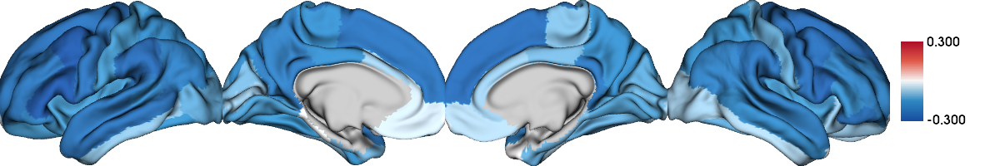

In [12]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-0.3, 0.3))

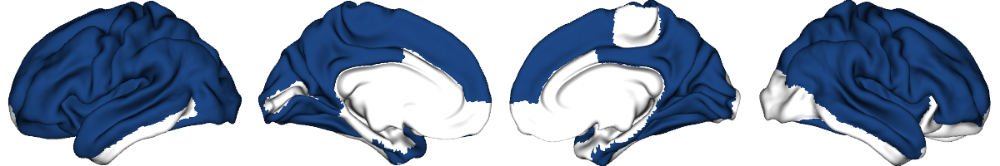

In [14]:
# plot p-sig areas in TLE

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [15]:
## Check which areas are significant
q_ctx_tle = pd.Series(male_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_entorhinal',
       'L_fusiform', 'L_inferiorparietal', 'L_isthmuscingulate',
       'L_lateraloccipital', 'L_lateralorbitofrontal', 'L_lingual',
       'L_middletemporal', 'L_paracentral', 'L_parsopercularis',
       'L_parsorbitalis', 'L_parstriangularis', 'L_postcentral',
       'L_posteriorcingulate', 'L_precentral', 'L_precuneus',
       'L_rostralmiddlefrontal', 'L_superiorfrontal', 'L_superiorparietal',
       'L_superiortemporal', 'L_supramarginal', 'L_temporalpole',
       'L_transversetemporal', 'L_insula', 'R_bankssts',
       'R_caudalmiddlefrontal', 'R_cuneus', 'R_entorhinal', 'R_fusiform',
       'R_inferiorparietal', 'R_isthmuscingulate', 'R_lingual',
       'R_middletemporal', 'R_parahippocampal', 'R_parsopercularis',
       'R_parsorbitalis', 'R_parstriangularis', 'R_pericalcarine',
       'R_postcentral', 'R_posteriorcingulate', 'R_precentral', 'R_precuneus',
       'R_rostralmiddlefrontal', 'R_superiorfront

In [16]:
len(q_ctx_tle[q_ctx_tle < 0.05])

52

In [17]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_ctx'][0].min(), male_metrics['cohen_ctx'][0].max()

(-0.31015723027620834, 0.004130392043302405)

IGE

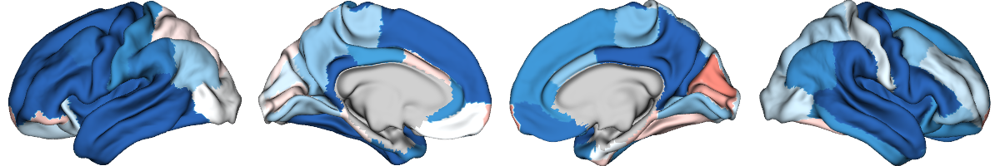

In [19]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

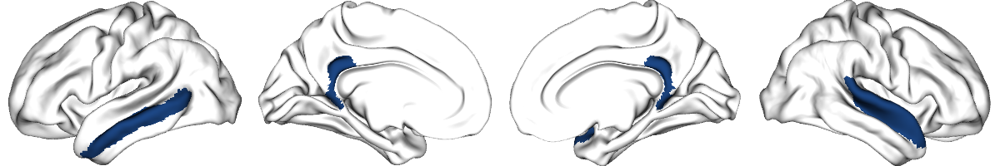

In [20]:
# plot p-sig areas in IGE
p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [21]:
## Check which areas are significant
q_ctx_ige = pd.Series(male_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_isthmuscingulate', 'L_middletemporal', 'R_isthmuscingulate',
       'R_superiortemporal'],
      dtype='object')

In [22]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_ctx'][1].min(), male_metrics['cohen_ctx'][1].max()

(-0.5774778779691095, 0.11987407550607708)

Subcortical volumes in TLE

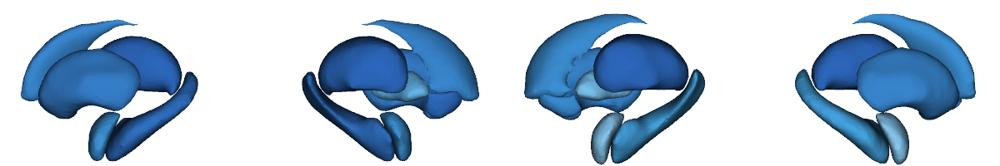

In [24]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

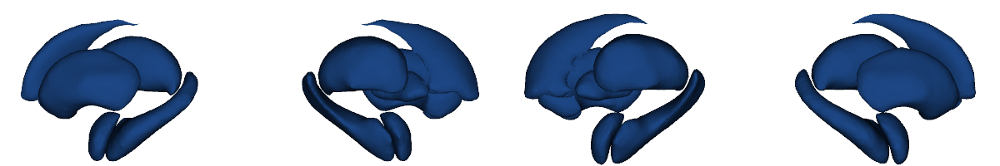

In [25]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [26]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(male_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [27]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_sv'][0].min(), male_metrics['cohen_sv'][0].max()

(-0.3492665525557586, -0.10102405069762968)

IGE

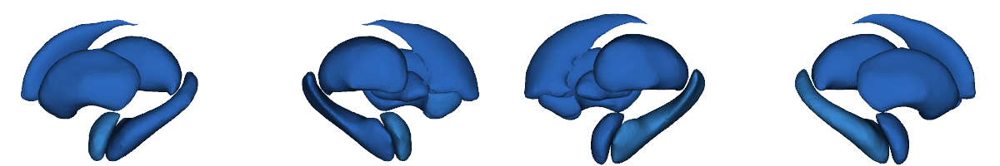

In [29]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

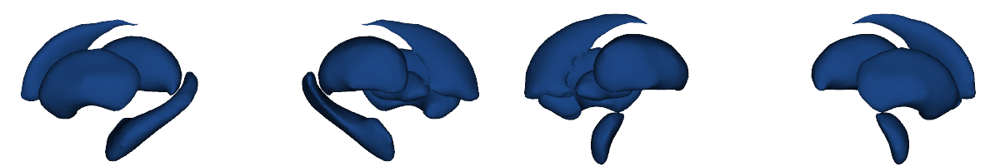

In [30]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), ventricles=False, zoom=1.8,  interactive=False, embed_nb=True, 
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [35]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(male_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05]

Lcaud      0.002050
Lhippo     0.005621
Lpal       0.004426
Lput       0.000091
Lthal      0.000005
Raccumb    0.003531
Ramyg      0.040292
Rcaud      0.003363
Rpal       0.008760
Rput       0.000089
Rthal      0.000020
Name: pFDR, dtype: float64

In [34]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_sv'][1].min(), male_metrics['cohen_sv'][1].max()

(-0.7705030776476508, -0.22530256208557478)

## Effects of disease duration in females

In [36]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

female_diagnosis = {}

for epi in ['tle', 'ige']:
    female_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        female_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        female_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col='durill', ao_col='ao', sex_col='Sex',
            age_col='Age', icv_col='ICV', gender='female', correlate_variable='durill'
        )

In [37]:
## reorganize the result
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

female_metrics = {}

for metric in metrics:
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        female_metrics[key] = None

for metric in metrics:
    metric_key = f"{metric}_values" if metric != 'cohen' else 'cohen_d'

    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'

        stacked_values = []
        for epi in epi_types:
            stacked_values.append(female_diagnosis[epi][biomarker][metric_key])
        
        female_metrics[key] = np.vstack(stacked_values)

Cortical thickness in TLE

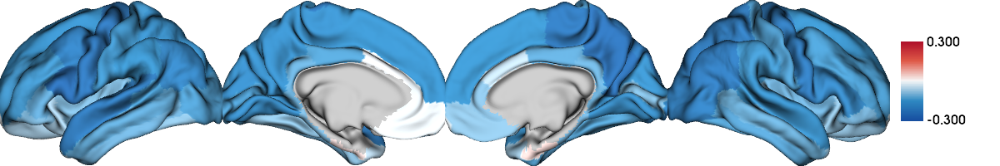

In [38]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-0.3, 0.3))

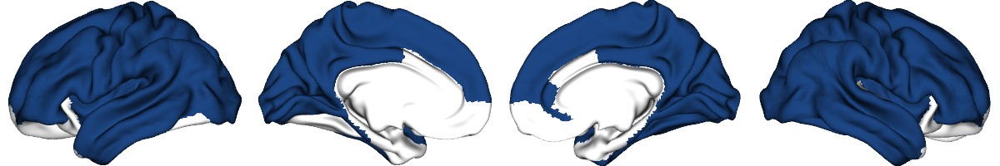

In [40]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [41]:
## Check which areas are significant
q_ctx_tle = pd.Series(female_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_inferiorparietal',
       'L_inferiortemporal', 'L_isthmuscingulate', 'L_lateraloccipital',
       'L_lingual', 'L_middletemporal', 'L_parahippocampal', 'L_paracentral',
       'L_parsopercularis', 'L_parsorbitalis', 'L_parstriangularis',
       'L_pericalcarine', 'L_postcentral', 'L_posteriorcingulate',
       'L_precentral', 'L_precuneus', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_superiorparietal', 'L_superiortemporal',
       'L_supramarginal', 'L_transversetemporal', 'L_insula', 'R_bankssts',
       'R_caudalmiddlefrontal', 'R_cuneus', 'R_fusiform', 'R_inferiorparietal',
       'R_inferiortemporal', 'R_isthmuscingulate', 'R_lateraloccipital',
       'R_lingual', 'R_middletemporal', 'R_parahippocampal', 'R_paracentral',
       'R_parsopercularis', 'R_parsorbitalis', 'R_parstriangularis',
       'R_pericalcarine', 'R_postcentral', 'R_posteriorcingulate',
       'R_precentral', 'R_precuneus', 'R_rostralanteri

In [42]:
len(q_ctx_tle[q_ctx_tle < 0.05])

53

In [43]:
# get the cohen's d values range for TLE in females
female_metrics['cohen_ctx'][0].min(), female_metrics['cohen_ctx'][0].max()

(-0.24829702787158053, 0.033575059253756395)

IGE

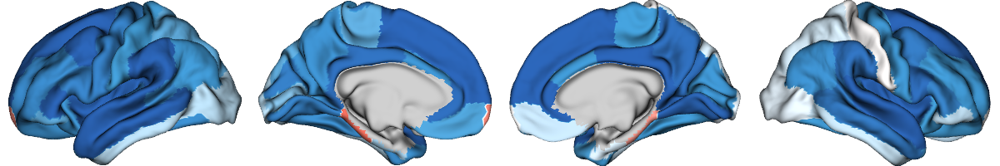

In [45]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

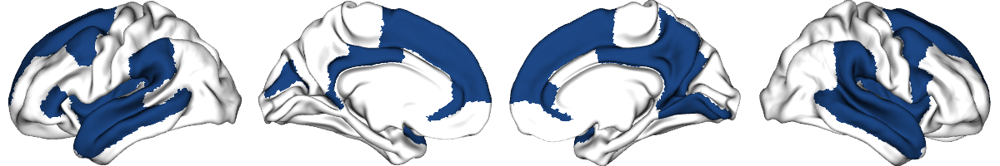

In [46]:
# plot p-sig areas in IGE

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [47]:
## Check which areas are significant
q_ctx_ige = pd.Series(female_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_caudalmiddlefrontal', 'L_cuneus', 'L_isthmuscingulate',
       'L_middletemporal', 'L_parstriangularis', 'L_posteriorcingulate',
       'L_rostralanteriorcingulate', 'L_superiorfrontal', 'L_superiortemporal',
       'L_supramarginal', 'L_insula', 'R_bankssts', 'R_caudalmiddlefrontal',
       'R_isthmuscingulate', 'R_lingual', 'R_middletemporal',
       'R_parsopercularis', 'R_posteriorcingulate', 'R_precuneus',
       'R_rostralanteriorcingulate', 'R_superiorfrontal', 'R_superiortemporal',
       'R_supramarginal', 'R_insula'],
      dtype='object')

In [48]:
len(q_ctx_ige[q_ctx_ige < 0.05])

24

In [49]:
# get the cohen's d values range for IGE in males
female_metrics['cohen_ctx'][1].min(), female_metrics['cohen_ctx'][1].max()

(-0.44216147083312746, 0.14634304373060536)

subcortical volumes

TLE

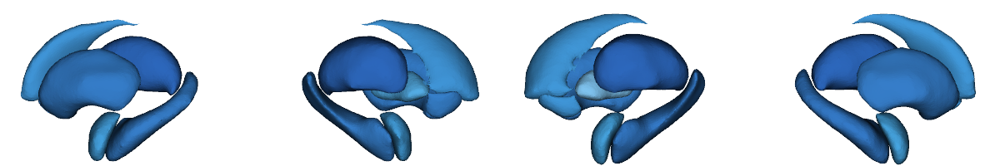

In [51]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

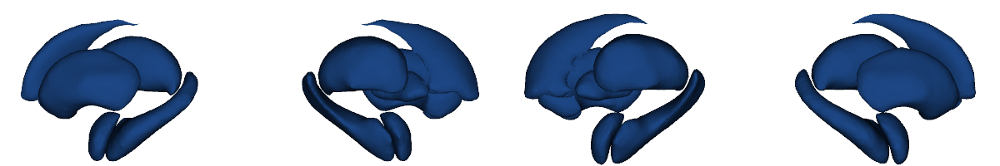

In [52]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [53]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(female_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [54]:
# get the cohen's d values range for TLE in males
female_metrics['cohen_sv'][0].min(), female_metrics['cohen_sv'][0].max()

(-0.3437817031890731, -0.1090784636417718)

IGE

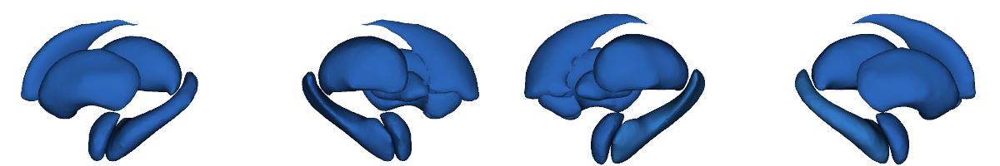

In [56]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))


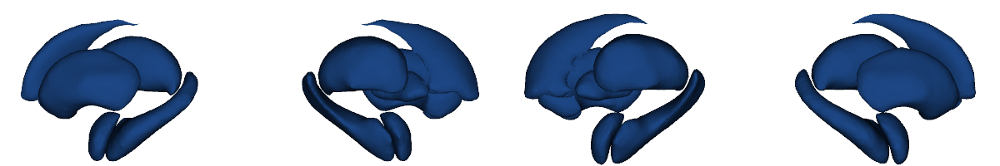

In [57]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [58]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(female_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [59]:
# get the cohen's d values range for IGE in males
female_metrics['cohen_sv'][1].min(), female_metrics['cohen_sv'][1].max()

(-0.6275743531082977, -0.25468187534043474)

## Effects of age of onset in males

In [61]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

male_diagnosis = {}

for epi in ['tle', 'ige']:
    male_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        male_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        male_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col='durill', ao_col='ao', age_col='Age',
            sex_col='Sex', icv_col='ICV', gender='male', correlate_variable='ao'
        )

In [62]:
## reorganize the result
metric_key_map = {
    't': 't_values',
    'p': 'p_values',
    'q': 'q_values',
    'cohen': 'cohen_d'
}

epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']
metrics = ['t', 'q', 'cohen']

male_metrics = {}

for metric in metrics:
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        male_metrics[key] = None

for metric in metrics:
    metric_key = metric_key_map[metric]

    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        stacked_values = []

        for epi in epi_types:
            stacked_values.append(
                male_diagnosis[epi][biomarker][metric_key]
            )

        male_metrics[key] = np.vstack(stacked_values)

Cortical thickness in TLE

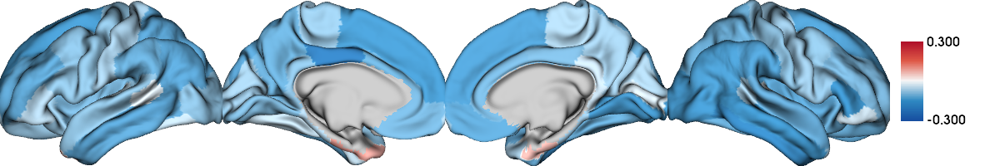

In [63]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-0.3, 0.3))

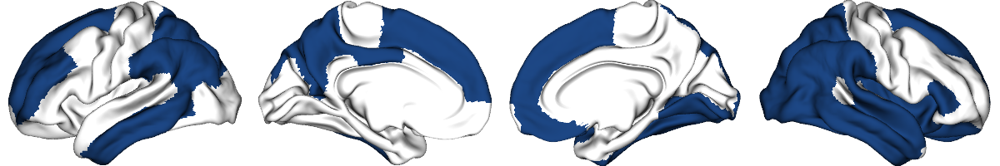

In [64]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [65]:
## Check which areas are significant
q_ctx_tle = pd.Series(male_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_inferiorparietal', 'L_inferiortemporal', 'L_middletemporal',
       'L_posteriorcingulate', 'L_precuneus', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_superiorparietal', 'L_supramarginal',
       'R_fusiform', 'R_inferiorparietal', 'R_inferiortemporal',
       'R_lateraloccipital', 'R_lateralorbitofrontal', 'R_lingual',
       'R_medialorbitofrontal', 'R_middletemporal', 'R_parstriangularis',
       'R_superiorfrontal', 'R_superiorparietal', 'R_superiortemporal',
       'R_supramarginal', 'R_insula'],
      dtype='object')

In [66]:
len(q_ctx_tle[q_ctx_tle < 0.05])

23

In [67]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_ctx'][0].min(), male_metrics['cohen_ctx'][0].max()

(-0.2012947589532337, 0.08931363083555745)

IGE

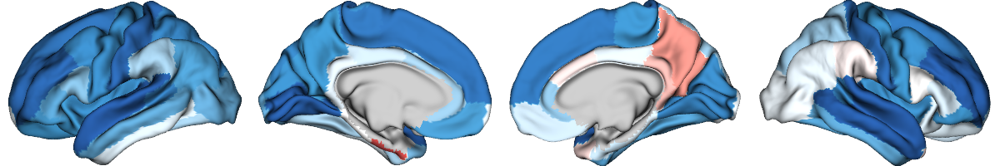

In [68]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

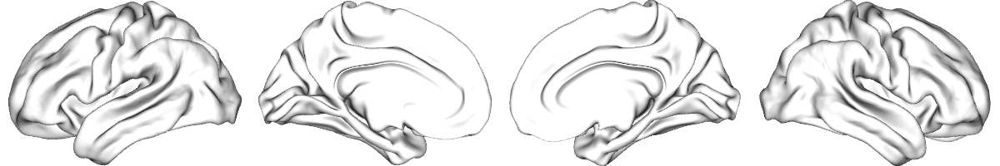

In [69]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [70]:
## Check which areas are significant
q_ctx_ige = pd.Series(male_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05]

Series([], Name: pFDR, dtype: float64)

In [71]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_ctx'][1].min(), male_metrics['cohen_ctx'][1].max()

(-0.3260621445142245, 0.19927541401626062)

Subcortical volumes in TLE

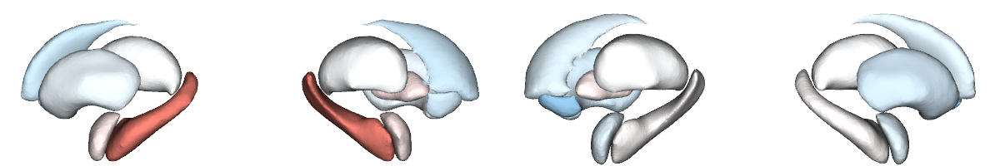

In [73]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

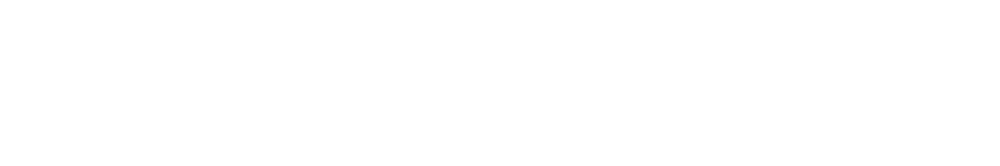

In [74]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [75]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(male_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [76]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_sv'][0].min(), male_metrics['cohen_sv'][0].max()

(-0.08822585843954396, 0.1275991149837614)

IGE

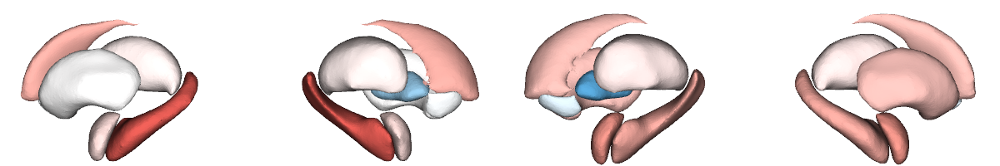

In [78]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

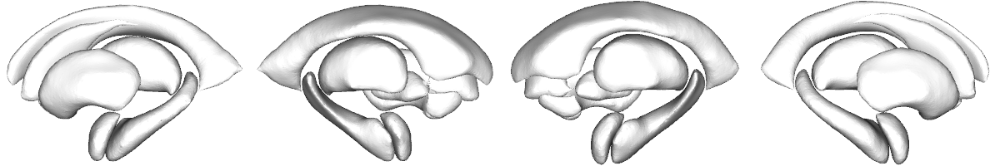

In [79]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), ventricles=False, zoom=1.8, nan_color=(1, 1, 1, 1), interactive=False, embed_nb=True, 
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [80]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(male_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05]

Series([], Name: pFDR, dtype: float64)

In [81]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_sv'][1].min(), male_metrics['cohen_sv'][1].max()

(-0.1312758043054179, 0.17593542615309937)

## Effects of age of onset in females

In [82]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

female_diagnosis = {}

for epi in ['tle', 'ige']:
    female_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        female_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        female_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col='durill', ao_col='ao', age_col='Age',
            sex_col='Sex', icv_col='ICV', gender='female', correlate_variable='ao'
        )

In [83]:
## reorganize the result
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

female_metrics = {}

for metric in metrics:
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        female_metrics[key] = None

for metric in metrics:
    metric_key = f"{metric}_values" if metric != 'cohen' else 'cohen_d'

    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'

        stacked_values = []
        for epi in epi_types:
            stacked_values.append(female_diagnosis[epi][biomarker][metric_key])
        
        female_metrics[key] = np.vstack(stacked_values)

Cortical thickness in TLE

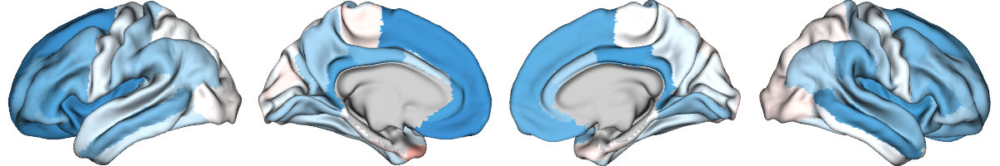

In [84]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

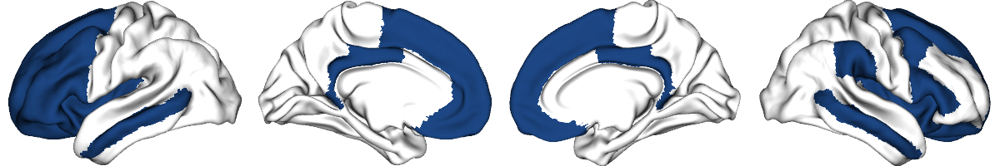

In [85]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [86]:
## Check which areas are significant
q_ctx_tle = pd.Series(female_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_caudalmiddlefrontal', 'L_isthmuscingulate', 'L_lateralorbitofrontal',
       'L_medialorbitofrontal', 'L_middletemporal', 'L_parsopercularis',
       'L_parsorbitalis', 'L_parstriangularis', 'L_posteriorcingulate',
       'L_rostralanteriorcingulate', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_frontalpole', 'L_insula',
       'R_caudalmiddlefrontal', 'R_isthmuscingulate', 'R_lateralorbitofrontal',
       'R_medialorbitofrontal', 'R_middletemporal', 'R_parsopercularis',
       'R_parstriangularis', 'R_posteriorcingulate', 'R_superiorfrontal',
       'R_supramarginal', 'R_frontalpole', 'R_insula'],
      dtype='object')

In [87]:
len(q_ctx_tle[q_ctx_tle < 0.05])

26

In [88]:
# get the cohen's d values range for TLE in males
female_metrics['cohen_ctx'][0].min(), female_metrics['cohen_ctx'][0].max()

(-0.18834791104812526, 0.08604739780273146)

IGE

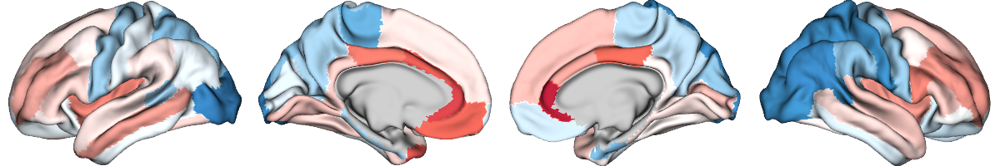

In [90]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

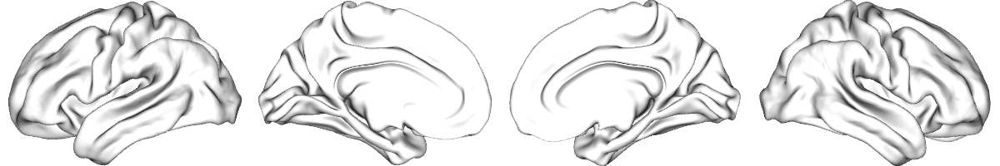

In [91]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [92]:
## Check which areas are significant
q_ctx_ige = pd.Series(female_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index([], dtype='object')

In [93]:
len(q_ctx_ige[q_ctx_ige < 0.05])

0

In [94]:
# get the cohen's d values range for IGE in males
female_metrics['cohen_ctx'][1].min(), female_metrics['cohen_ctx'][1].max()

(-0.19838451025120044, 0.3053187460053109)

Subcortical volumes in TLE

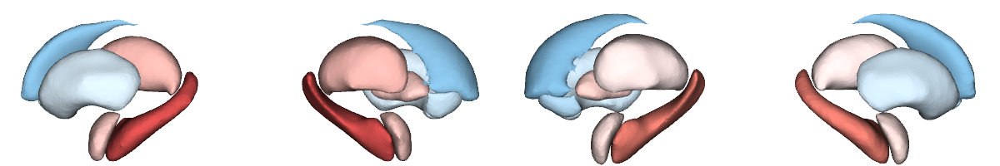

In [96]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

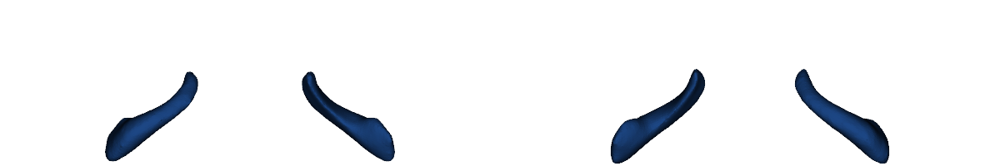

In [97]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [98]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(female_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Lhippo', 'Rhippo'], dtype='object')

In [99]:
# get the cohen's d values range for TLE in males
female_metrics['cohen_sv'][0].min(), female_metrics['cohen_sv'][0].max()

(-0.10042265251358412, 0.20119024932252733)

IGE

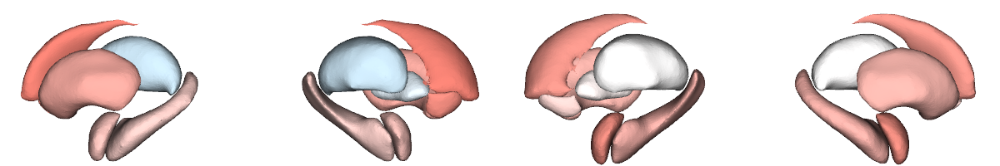

In [101]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

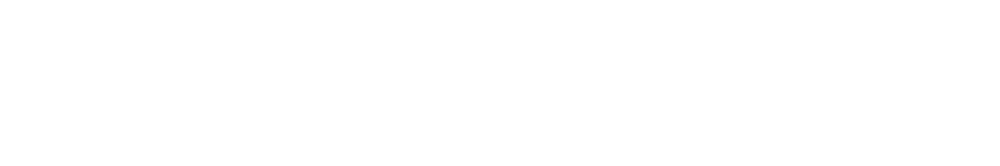

In [102]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [103]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(female_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index([], dtype='object')

In [104]:
# get the cohen's d values range for IGE in males
female_metrics['cohen_sv'][1].min(), female_metrics['cohen_sv'][1].max()

(-0.0439271956374623, 0.12814232635812045)

## clinical correlate, and clinical variables-by sex interaction effects

In [106]:
# glm comparison
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['duration', 'duration_sex_interaction', 'ao', 'ao_sex_interaction']

results = {}
for epi in ['tle', 'ige']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill='durill',
                ao='ao', age='Age', sex='Sex', icv='ICV'
            )

2026-05-27 19:41:11,503 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-27 19:41:11,541 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-27 19:41:11,606 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-27 19:41:11,642 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [107]:
# reorganize the results
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

result_dicts = {}
for epi in epi_types:
    for metric in metrics:
        for biomarker in biomarkers:
            key = f"{metric}_{epi}_{biomarker}"
            result_dicts[key] = {}

for epi in epi_types:
    for biomarker in biomarkers:
        # t values
        t_values = np.vstack([
            results[epi][biomarker]['duration']['t_values'],
            results[epi][biomarker]['duration_sex_interaction']['t_values'],
            results[epi][biomarker]['ao']['t_values'],
            results[epi][biomarker]['ao_sex_interaction']['t_values']
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values
        
        # q values
        q_values = np.vstack([
            results[epi][biomarker]['duration']['q_values'],
            results[epi][biomarker]['duration_sex_interaction']['q_values'],
            results[epi][biomarker]['ao']['q_values'],
            results[epi][biomarker]['ao_sex_interaction']['q_values']
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values
        
        # cohen's d
        cohen_values = np.vstack([
            results[epi][biomarker]['duration']['cohen_d'],
            results[epi][biomarker]['duration_sex_interaction']['cohen_d'],
            results[epi][biomarker]['ao']['cohen_d'],
            results[epi][biomarker]['ao_sex_interaction']['cohen_d']
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values

Sex duration interaction effects in cortical thickness in TLE

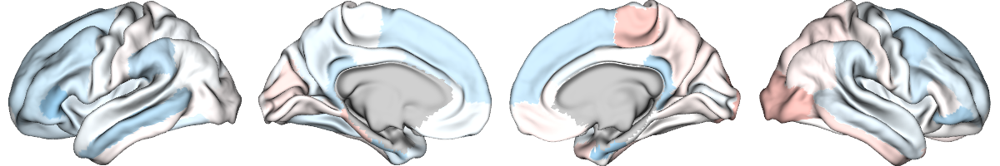

In [108]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

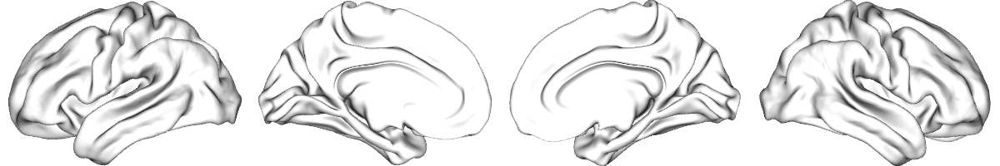

In [109]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [110]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [111]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [112]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_ctx'][1].min(), result_dicts['cohen_tle_ctx'][1].max()

(-0.08295016572941136, 0.06428124187664405)

Sex * age of onset interaction effects 

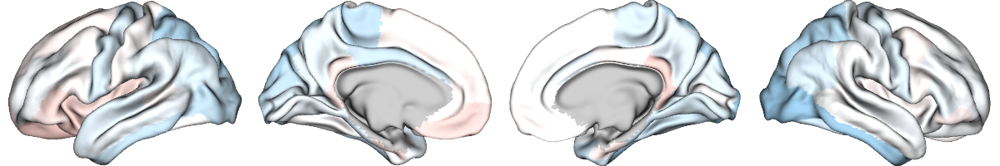

In [114]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

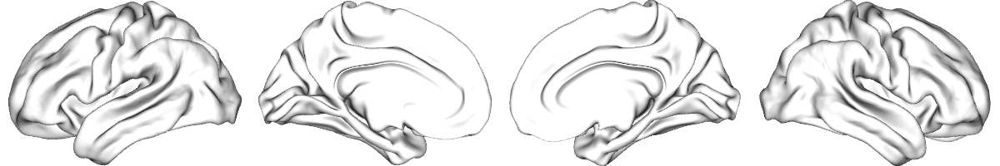

In [115]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [116]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [117]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [118]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_ctx'][3].min(), result_dicts['cohen_tle_ctx'][3].max()

(-0.08191524695450443, 0.04854332791776418)

subcortical volume

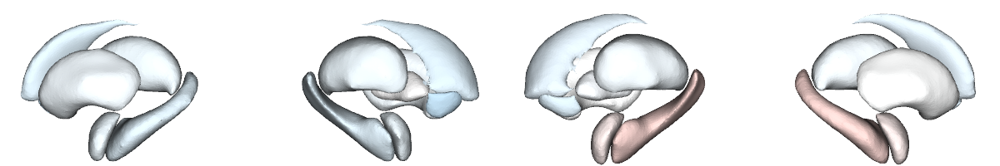

In [121]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

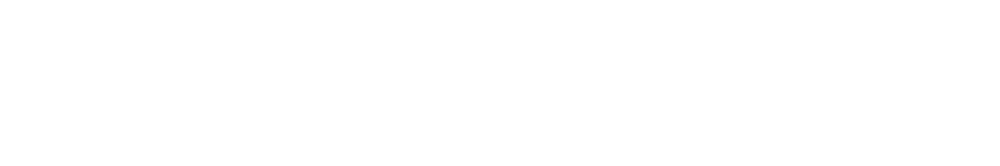

In [122]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

Sex* age of onset interaction effects in TLE

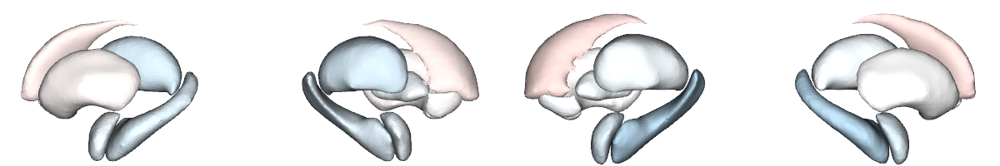

In [123]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

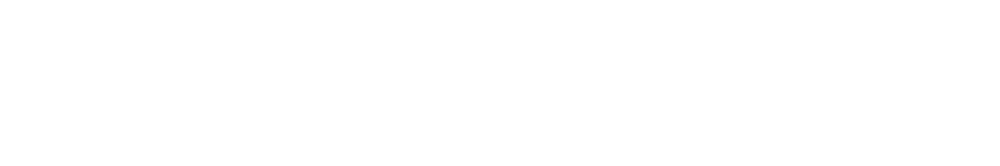

In [124]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [125]:
## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [126]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [127]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][3].min(), result_dicts['cohen_tle_sv'][3].max()

(-0.057606336528943626, 0.03426530514489231)

Sex duration interaction effects in cortical thickness in TGE

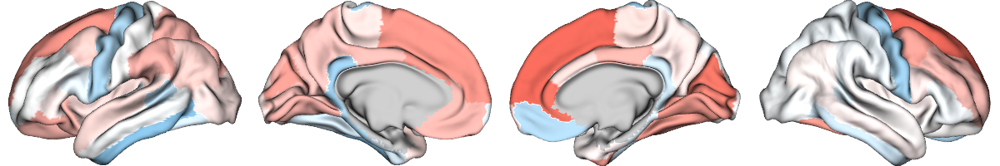

In [129]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_ige_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

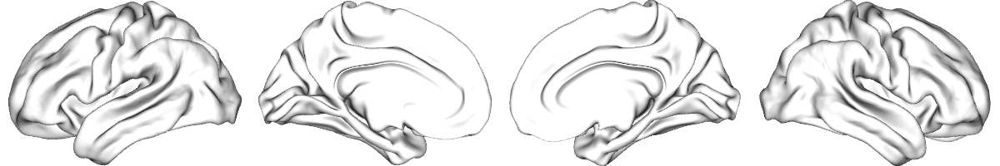

In [130]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [131]:
## Check which areas are significant in epilepsy
q_ctx_ige = pd.Series(result_dicts['q_ige_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index([], dtype='object')

In [132]:
len(q_ctx_ige[q_ctx_ige < 0.05])

0

In [134]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_ctx'][1].min(), result_dicts['cohen_ige_ctx'][1].max()

(-0.09438360276156509, 0.1542427854439101)

Sex age of onset interaction effects in interaction

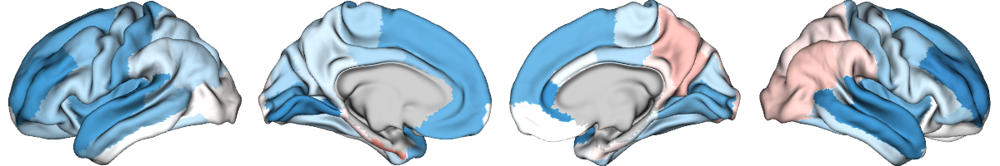

In [136]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_ige_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

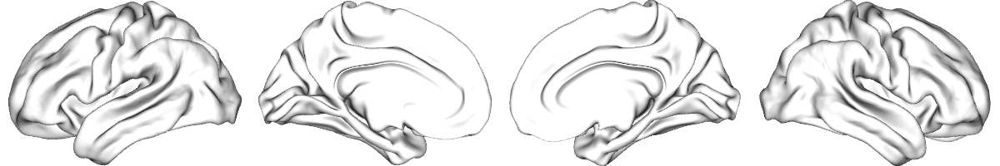

In [137]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [138]:
## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_ige_ctx'][3], index=ctx_ige.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [139]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [140]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_ctx'][3].min(), result_dicts['cohen_ige_ctx'][3].max()

(-0.18305939423975423, 0.1064631734359365)

Subcortical volume

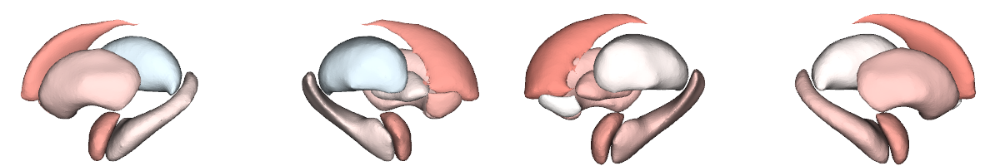

In [142]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_ige_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

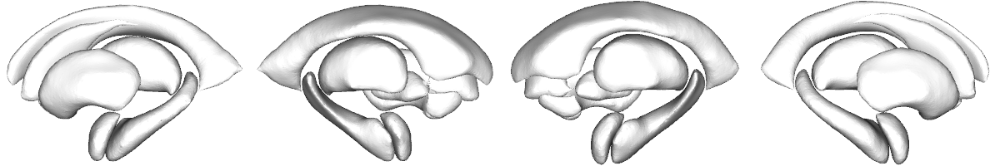

In [144]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

Sex age of onset interaction effects

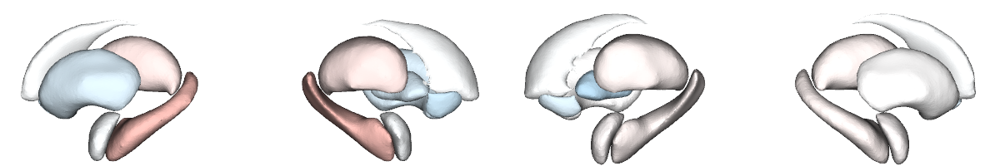

In [145]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_ige_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

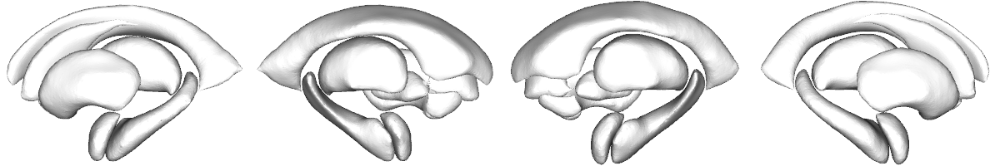

In [146]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [147]:
## Check which areas are significant in epilepsy
q_sv_hc = pd.Series(result_dicts['q_ige_sv'][3], index=sv_ige.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index([], dtype='object')

In [148]:
len(q_sv_hc[q_sv_hc < 0.05])

0

In [149]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_sv'][3].min(), result_dicts['cohen_ige_sv'][3].max()

(-0.05781982848966845, 0.06682345815694417)